# 3. Propagation of uncertainty

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapter 1, partial derivatives

**Reading:** Taylor, ch. 3 · Bevington & Robinson, ch. 3 · Fornasini, ch.
8.1–8.3 · Rouaud, ch. II.B · GUM, clause 5.1

Most quantities of interest are not measured directly. A density is
computed from a mass and some lengths, a rate constant from concentrations
and times, a viscosity from a falling time. If the inputs are uncertain, so
is the output. *Propagation of uncertainty* is the rule that carries the
input uncertainties through the formula.

In this notebook we

1. derive the propagation formula for one and for several input quantities;
2. obtain the familiar rules for sums, products and powers as special cases;
3. work a complete example by hand, with the helper functions, and by
   simulation;
4. organise the result as an *uncertainty budget* that shows which input
   matters;
5. look at the classic trap of subtracting two nearly equal numbers.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(2)

## 3.1 One input quantity

Let $y = f(x)$ and suppose the measured value $x$ differs from the true
value by a small error $\delta x$. Expanding $f$ about the measured value,

$$ f(x + \delta x) = f(x) + f'(x)\,\delta x + \tfrac12 f''(x)\,\delta x^2 + \dots $$

If $\delta x$ is small enough for the curve to be replaced by its tangent
over the range of interest, the error in $y$ is

$$ \delta y \approx f'(x)\,\delta x . $$

The error is simply multiplied by the slope. Taking the standard deviation
of both sides gives the rule for one variable,

$$ u_y = |f'(x)|\,u_x . $$

The derivative $f'(x)$ is called the **sensitivity coefficient**: it tells
how strongly the output responds to the input. Panel (a) of the figure in
Section 3.4 shows this geometrically.

Two examples. For the area of a circle, $A = \pi r^2$, we have
$u_A = 2\pi r\,u_r$, or in relative terms $u_A/A = 2\,u_r/r$: a 1 % uncertainty
in the radius becomes 2 % in the area. For $y = \ln x$ we have $u_y = u_x/x$:
the uncertainty of a logarithm is the *relative* uncertainty of its argument.

## 3.2 Several input quantities

Now let $y = f(x_1, x_2, \dots, x_n)$. The first-order expansion is

$$ \delta y \approx \sum_{i=1}^{n} \frac{\partial f}{\partial x_i}\,\delta x_i
   \equiv \sum_i c_i\,\delta x_i , $$

with sensitivity coefficients $c_i = \partial f/\partial x_i$ evaluated at
the measured values. We want the variance of $\delta y$, so we square and
average over many imagined repetitions of the whole experiment:

$$ \langle \delta y^2 \rangle
 = \sum_i c_i^2 \langle \delta x_i^2\rangle
 + \sum_{i \ne j} c_i c_j \langle \delta x_i\,\delta x_j\rangle . $$

The averages $\langle\delta x_i^2\rangle = u_i^2$ are the input variances.
The cross terms $\langle\delta x_i\,\delta x_j\rangle$ are the
*covariances*. If the inputs are measured independently, a positive error
in one is as likely to be accompanied by a negative as by a positive error
in another, and the covariances vanish. We are left with the

> **Law of propagation of uncertainty (independent inputs)**
> $$ u_y^2 = \sum_{i=1}^{n} \left(\frac{\partial f}{\partial x_i}\right)^{2} u_i^2 . $$

Each input contributes $|c_i|\,u_i$, and the contributions add in
quadrature, just as in Section 1.4. Two assumptions went in, and both will
be revisited in Chapter 12
([Chapter 12](../part3_data_analysis/12_covariance_and_limits_of_linearisation.ipynb)):
the errors are small enough for the tangent approximation, and the inputs
are independent.

## 3.3 The rules for sums, products and powers

Three special cases cover most everyday calculations.

**Sums and differences.** For $y = a + b$ or $y = a - b$ the sensitivity
coefficients are $\pm 1$, so

$$ u_y^2 = u_a^2 + u_b^2 . $$

*Absolute* uncertainties add in quadrature, for a difference as well as for
a sum. An uncertainty never subtracts.

**Products and quotients.** For $y = ab$ we have
$\partial y/\partial a = b = y/a$ and $\partial y/\partial b = y/b$, so
$u_y^2 = (y/a)^2u_a^2 + (y/b)^2u_b^2$. Dividing by $y^2$,

$$ \left(\frac{u_y}{y}\right)^{2} = \left(\frac{u_a}{a}\right)^{2} + \left(\frac{u_b}{b}\right)^{2} , $$

and the same result holds for $y = a/b$. *Relative* uncertainties add in
quadrature.

**Powers.** For $y = a^n$, $\partial y/\partial a = n a^{n-1} = n y/a$, so

$$ \frac{u_y}{|y|} = |n|\,\frac{u_a}{|a|} . $$

Combining the last two: for a general product of powers
$y = C\,a^{p}\,b^{q}\,c^{r}\cdots$ with an exact constant $C$,

$$ \left(\frac{u_y}{y}\right)^{2}
 = p^2\left(\frac{u_a}{a}\right)^{2} + q^2\left(\frac{u_b}{b}\right)^{2} + r^2\left(\frac{u_c}{c}\right)^{2} + \dots $$

This one formula handles a large share of the laboratory formulas in
physics, chemistry and engineering. Quantities raised to high powers
deserve the most careful measurement.

## 3.4 Worked example: the density of a metal cylinder

A cylinder is weighed on a balance and measured with a calliper:

| Quantity | Value | Standard uncertainty |
|---|---|---|
| mass $m$ | 23.45 g | 0.01 g |
| diameter $d$ | 9.98 mm | 0.02 mm |
| height $h$ | 35.10 mm | 0.05 mm |

The density is

$$ \rho = \frac{m}{V} = \frac{4m}{\pi d^2 h} . $$

**By hand.** This is a product of powers with exponents $+1$, $-2$ and
$-1$, so

$$ \left(\frac{u_\rho}{\rho}\right)^{2}
 = \left(\frac{u_m}{m}\right)^{2} + 4\left(\frac{u_d}{d}\right)^{2} + \left(\frac{u_h}{h}\right)^{2} . $$

In [2]:
m, u_m = 23.45e-3, 0.01e-3      # kg
d, u_d = 9.98e-3, 0.02e-3       # m
h, u_h = 35.10e-3, 0.05e-3      # m

rho = 4 * m / (np.pi * d**2 * h)
rel = np.sqrt((u_m / m)**2 + 4 * (u_d / d)**2 + (u_h / h)**2)

print(f"relative uncertainties: m {u_m/m:.3%},  d {u_d/d:.3%},  h {u_h/h:.3%}")
print(f"rho = {rho:.1f} kg/m^3,  relative uncertainty {rel:.2%}")
print("rho =", ep.format_result(rho, rel * rho, "kg/m^3"))

relative uncertainties: m 0.043%,  d 0.200%,  h 0.142%
rho = 8540.5 kg/m^3,  relative uncertainty 0.43%
rho = 8541 ± 37 kg/m^3


**With the helper function.** `ep.propagate` evaluates the same formula for
any function, obtaining the partial derivatives numerically (by changing
each input slightly and observing the change in the output). Nothing has to
be differentiated by hand, which matters when the formula is long.

In [3]:
def density(m, d, h):
    return 4 * m / (np.pi * d**2 * h)

x = [m, d, h]
u = [u_m, u_d, u_h]
rho, u_rho = ep.propagate(density, x, u)
print("rho =", ep.format_result(rho, u_rho, "kg/m^3"))

rho = 8541 ± 37 kg/m^3


**Uncertainty budget.** The total alone hides the most useful information:
which input is responsible. A budget lists, for each input, the contribution
$|c_i|u_i$ and its share of the output variance.

In [4]:
rows, rho, u_rho = ep.budget(density, x, u, names=["m (kg)", "d (m)", "h (m)"])
print(ep.format_budget(rows, rho, u_rho))

input             value           u    rel. u        |c| u    share
-------------------------------------------------------------------
m (kg)          0.02345       1e-05     0.04%         3.64     1.0%
d (m)           0.00998       2e-05     0.20%         34.2    87.9%
h (m)            0.0351       5e-05     0.14%         12.2    11.1%
-------------------------------------------------------------------
output           8540.5          37     0.43%


The diameter is responsible for almost 90 % of the variance, although its
relative uncertainty (0.20 %) is not much larger than that of the height
(0.14 %). The reason is the exponent: the diameter enters squared, so its
relative uncertainty counts double, and in the variance four times. A
better balance would improve nothing. A micrometer for the diameter would.

**By simulation.** The propagation formula is an approximation. A direct
check is to simulate the experiment many times: draw each input from a
distribution with the stated uncertainty, compute the density for each
draw, and look at the spread of the results. This is the Monte Carlo method.

In [5]:
samples = ep.monte_carlo(density, x, u, n=200_000, rng=rng)
mc = ep.summarize(samples)
print(f"Monte Carlo : mean {mc['mean']:.1f}, standard deviation {mc['std']:.1f} kg/m^3")
print(f"Formula     : rho  {rho:.1f}, uncertainty        {u_rho:.1f} kg/m^3")

Monte Carlo : mean 8540.4, standard deviation 36.5 kg/m^3
Formula     : rho  8540.5, uncertainty        36.5 kg/m^3


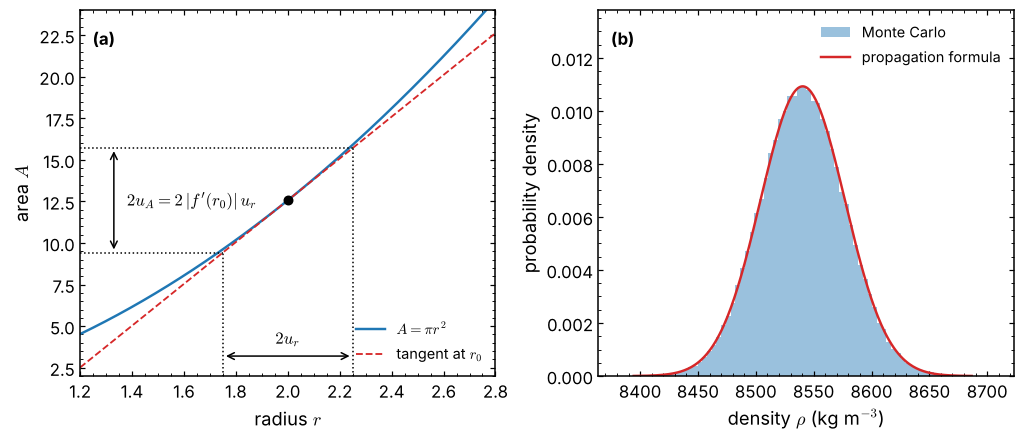

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.9))

# (a) one variable: an interval in x maps to an interval in y through the slope
ax = axes[0]
f = lambda r: np.pi * r**2
r0, ur = 2.0, 0.25
rr = np.linspace(1.2, 2.8, 200)
ax.plot(rr, f(rr), "C0", label=r"$A=\pi r^2$")
ax.plot(rr, f(r0) + 2 * np.pi * r0 * (rr - r0), "C3--", lw=1.2, label="tangent at $r_0$")
for s in (-1, 1):
    ax.plot([r0 + s * ur] * 2, [0, f(r0) + s * 2 * np.pi * r0 * ur], "k:", lw=1)
    ax.plot([1.2, r0 + s * ur], [f(r0) + s * 2 * np.pi * r0 * ur] * 2, "k:", lw=1)
ax.plot(r0, f(r0), "ko")
ax.annotate("", (r0 - ur, 3.2), (r0 + ur, 3.2), arrowprops=dict(arrowstyle="<->"))
ax.text(r0, 3.9, r"$2u_r$", ha="center")
ax.annotate("", (1.33, f(r0) - 2 * np.pi * r0 * ur), (1.33, f(r0) + 2 * np.pi * r0 * ur),
            arrowprops=dict(arrowstyle="<->"))
ax.text(1.38, f(r0), r"$2u_A = 2\,|f'(r_0)|\,u_r$", va="center")
ax.set_xlim(1.2, 2.8); ax.set_ylim(2, 24)
ax.set_xlabel("radius $r$"); ax.set_ylabel("area $A$")
ax.legend(loc="lower right"); ep.panel_label(ax, "(a)")

# (b) Monte Carlo histogram against the normal curve predicted by the formula
ax = axes[1]
ax.hist(samples, bins=80, density=True, color="C0", alpha=0.45, label="Monte Carlo")
g = np.linspace(rho - 4 * u_rho, rho + 4 * u_rho, 300)
ax.plot(g, np.exp(-0.5 * ((g - rho) / u_rho)**2) / (u_rho * np.sqrt(2 * np.pi)),
        "C3", label="propagation formula")
ax.set_xlabel(r"density $\rho$ (kg m$^{-3}$)"); ax.set_ylabel("probability density")
ax.set_ylim(0, 0.0138)
ax.legend(loc="upper right"); ep.panel_label(ax, "(b)")
plt.show()

Formula and simulation agree to within the statistical noise of the
simulation. This is the normal situation when relative uncertainties are a
fraction of a per cent: over such a small range every smooth function is
practically a straight line. The agreement fails when uncertainties are
large or the function is strongly curved, and Monte Carlo then becomes the
method of choice
([Chapter 12](../part3_data_analysis/12_covariance_and_limits_of_linearisation.ipynb)).

## 3.5 A trap: the difference of two nearly equal numbers

For a difference $y = a - b$ the absolute uncertainty is
$\sqrt{u_a^2 + u_b^2}$ whatever the values of $a$ and $b$. The *relative*
uncertainty, however, is

$$ \frac{u_y}{|y|} = \frac{\sqrt{u_a^2 + u_b^2}}{|a - b|} , $$

and it grows without limit as $a$ and $b$ approach each other.

Example: the mass of a liquid sample is found by weighing a beaker full
(152.36 g) and empty (150.21 g), each to ±0.01 g. Each weighing is good to
0.007 %. The sample mass is 2.15 g ± 0.014 g, which is 0.66 %: a hundred
times worse in relative terms. The same thing happens when a small
temperature rise is obtained from two thermometer readings, a reaction
enthalpy from two large enthalpies of formation, or an adsorption energy
from three large total energies.

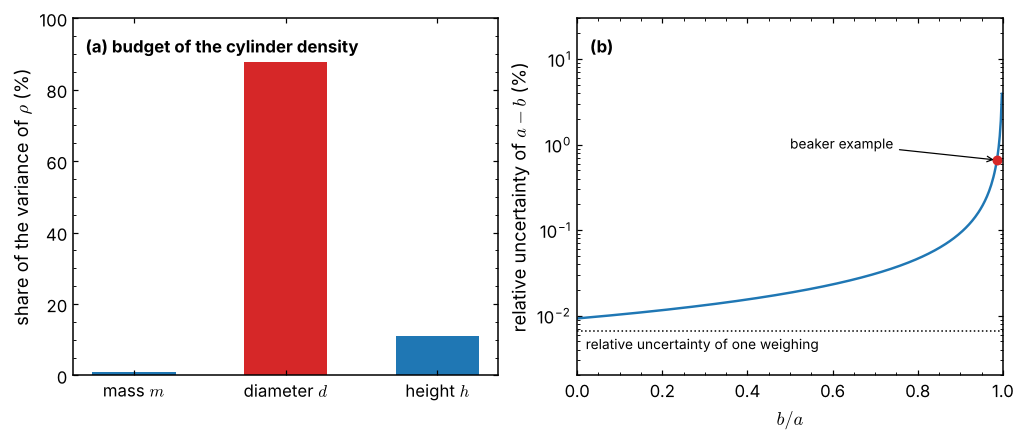

In [7]:
a, u_a = 152.36, 0.01
b_values = np.linspace(0, 152.0, 400)
rel_diff = np.hypot(u_a, u_a) / (a - b_values)

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.9))
ax = axes[0]
shares = [r["variance_fraction"] * 100 for r in rows]
ax.bar(["mass $m$", "diameter $d$", "height $h$"], shares, color=["C0", "C3", "C0"], width=0.55)
ax.set_ylabel("share of the variance of $\\rho$ (%)"); ax.set_ylim(0, 100)
ax.tick_params(axis="x", which="minor", bottom=False, top=False)
ep.panel_label(ax, "(a) budget of the cylinder density")

ax = axes[1]
ax.semilogy(b_values / a, rel_diff * 100, "C0")
ax.axhline(u_a / a * 100, color="k", ls=":", lw=1)
ax.text(0.02, u_a / a * 100 * 0.62, "relative uncertainty of one weighing", fontsize=9)
ax.plot(150.21 / a, np.hypot(u_a, u_a) / 2.15 * 100, "C3o")
ax.annotate("beaker example", (150.21 / a, 0.66), (0.50, 0.9), fontsize=9,
            arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set_xlabel("$b/a$"); ax.set_ylabel("relative uncertainty of $a-b$ (%)")
ax.set_xlim(0, 1); ax.set_ylim(2e-3, 30)
ep.panel_label(ax, "(b)", x=0.03, y=0.95)
plt.show()

The remedy is to design the measurement so that the small quantity is
measured directly (weigh the sample on a tared balance, use a differential
thermometer) or so that the errors of $a$ and $b$ are common to both and
cancel, a case treated in
[Chapter 12](../part3_data_analysis/12_covariance_and_limits_of_linearisation.ipynb).

## Summary

* To first order, each input contributes $|\partial f/\partial x_i|\,u_i$
  to the output, and independent contributions add in quadrature.
* Sums and differences: absolute uncertainties in quadrature. Products and
  quotients: relative uncertainties in quadrature. Powers: multiply the
  relative uncertainty by $|n|$.
* An uncertainty budget shows where the uncertainty comes from and where
  improvement would pay.
* A Monte Carlo simulation is an independent check that needs no calculus.
* Differences of nearly equal numbers lose relative precision.

## Exercises

1. The period of a pendulum is $T = 2\pi\sqrt{L/g}$. With $L = 0.750 \pm
   0.002$ m and $T = 1.738 \pm 0.004$ s, compute $g = 4\pi^2L/T^2$ and its
   uncertainty by hand and with `ep.propagate`. Which measurement should be
   improved first?
2. The resistance of a wire is $R = V/I$ and the power dissipated is
   $P = VI$. For $V = 5.02 \pm 0.02$ V and $I = 0.251 \pm 0.002$ A, find both
   with uncertainties. Why is it wrong to compute $P = I^2R$ from your $R$
   and propagate as if $I$ and $R$ were independent? (Try it, and compare.)
3. The pH of a solution is $-\log_{10}[\mathrm{H^+}]$. Show that an
   uncertainty of 0.02 in pH corresponds to a relative uncertainty of 4.6 %
   in the concentration.
4. Repeat the Monte Carlo check of Section 3.4 with every input uncertainty
   multiplied by 50. Does the formula still agree with the simulation? Is
   the histogram still symmetric?

---

**Previous:** [2. Measuring instruments](02_measuring_instruments.ipynb) &nbsp;·&nbsp; **Next:** [4. Repeated measurements](04_repeated_measurements.ipynb)